In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Problem 2

## 2.3
Let 𝑛 = 100 and simulate (𝑤𝑖, 𝑥𝑖, 𝑦𝑖), 𝑖 = 1, … , 𝑛 from ℙ. Compute and
report  ̂𝜏.

In [2]:
np.random.seed(42) # Seed for reproducibility

In [3]:
n: int = 100

samples = []
for _ in range(n):
    w_i = np.random.uniform(-2, 2)
    x_i = np.random.normal(w_i**4, 1)
    y_i = np.random.normal(x_i + w_i**2, w_i**2)

    samples.append((w_i, x_i, y_i))

samples = np.array(samples)

samples[0]

array([-0.50183952, -1.04845527, -0.71629911])

In [4]:
X = np.hstack([np.ones((samples.shape[0], 1)), samples[:, :2]])
y = samples[:, 2]

In [5]:
b, _, _, _ = np.linalg.lstsq(X, y, rcond=None)

tau = b[-1]
f"tau (hat): {tau:.4f}"

'tau (hat): 1.2364'

## 2.4
Repeat the simulation in Part 3 a total of 1000 times, generating a new
dataset each time. Show a histogram of the 1000 estimates ̂𝜏.

In [6]:
tau_estimates = []

for _ in range(1000):
    n: int = 100

    samples = []
    for _ in range(n):
        w_i = np.random.uniform(-2, 2)
        x_i = np.random.normal(w_i**4, 1)
        y_i = np.random.normal(x_i + w_i**2, w_i**2)

        samples.append((w_i, x_i, y_i))

    samples = np.array(samples)

    X = np.hstack([np.ones((samples.shape[0], 1)), samples[:, :2]])
    y = samples[:, 2]

    b, _, _, _ = np.linalg.lstsq(X, y, rcond=None)

    tau_estimates.append(b[-1])

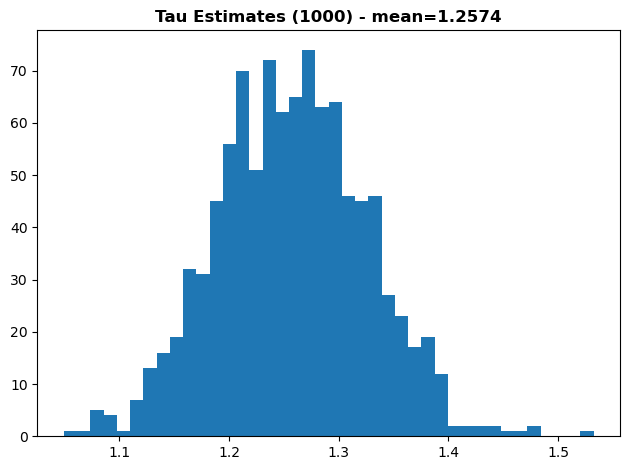

In [7]:
plt.hist(x = tau_estimates, bins = 40)
plt.title(f"Tau Estimates (1000) - mean={np.mean(tau_estimates):0.4f}", fontweight='bold')
plt.tight_layout()
plt.show()